# RQ1 (part 2): interpreting the route clusters

This notebook builds on `02_route_clustering_Approach_A.ipynb`. It does **not** re-run the clustering:
it reads the exported Model B clusters (`results/tables/02_route_clusters_model_b.csv`, built on January–June)
and adds four things:

1. **Plain names and a profile** for each of the 7 clusters.
2. **Delay levels with medians and percentiles**, as the group decided (the median and the 90th percentile are
   not pulled around by the few extreme delays of several hours).
3. **Delay causes per cluster** and what they say about delays spreading through the network.
4. **Runtime of hierarchical clustering against K-Means** as the number of routes grows (scalability part).

The cluster profiles were built **without** any delay information, so comparing delays afterwards is not circular.
Delay-cause columns are only used here to *describe* clusters, never as features.

**Data:** the notebook uses `data/processed/flights_2024_clean.parquet` when it exists. Otherwise it falls back to the
100,000-flight sample, which is only good for testing the code: the numbers for the report must come from the full data.

In [1]:
import os
import sys
import time
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import CLEAN_PARQUET, FIGURES_DIR, RANDOM_SEED, SAMPLE_PARQUET, TABLES_DIR
from src.cleaning import clean_flights
from src.data_loading import load_flights
from src.profiling import track

KEYS = ["origin", "dest", "op_unique_carrier"]
TRAIN_MONTHS = list(range(1, 7))
DELAY_CAUSES = ["carrier_delay", "weather_delay", "nas_delay", "security_delay", "late_aircraft_delay"]
CAUSE_LABELS = {
    "carrier_delay": "Airline",
    "weather_delay": "Weather",
    "nas_delay": "Air traffic system",
    "security_delay": "Security",
    "late_aircraft_delay": "Late incoming aircraft",
}
# Same features as Model B in notebook 02
FEATURES_B = ["mean_distance", "log_flights_per_week", "morning_share", "evening_night_share", "weekend_share"]

# Categorical colours, fixed order (validated default palette)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "axes.edgecolor": INK_MUTED, "axes.labelcolor": INK, "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10,
})

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

Matplotlib is building the font cache; this may take a moment.


## Load the flights and the exported clusters

Same flight filter as notebook 02: January–June, completed flights (not cancelled or diverted), valid scheduled departure time.

In [2]:
if CLEAN_PARQUET.exists():
    df = load_flights(CLEAN_PARQUET)
    DATA_SOURCE = "full"
else:
    df, _ = clean_flights(load_flights(SAMPLE_PARQUET))
    DATA_SOURCE = "sample"
    print("WARNING: full data not found, using the 100,000-flight sample.")
    print("         Fine for testing; do NOT use these numbers in the report.\n")

df = df.loc[df["month"].isin(TRAIN_MONTHS)]
flights = df.loc[
    (df["cancelled"] == 0)
    & (df["diverted"] == 0)
    & (df["distance"] > 0)
    & (df["crs_elapsed_time"] > 0)
    & df["arr_delay"].notna()
].copy()
dep_time = flights["crs_dep_time"]
flights = flights.loc[dep_time.notna() & dep_time.between(0, 2400) & ((dep_time % 100) < 60)].copy()
flights["late_15"] = (flights["arr_delay"] >= 15).astype(int)
for col in KEYS:
    flights[col] = flights[col].astype(str)

routes = pd.read_csv(TABLES_DIR / "02_route_clusters_model_b.csv")
n_clusters = routes["cluster"].nunique()

flights = flights.merge(routes[KEYS + ["cluster"]], on=KEYS, how="inner", validate="many_to_one")

print(f"Data source: {DATA_SOURCE}")
print(f"Route-airline pairs with a cluster: {len(routes):,} in {n_clusters} clusters "
      f"(minimum flights per pair in the export: {routes['n_flights'].min()})")
print(f"Completed January-June flights on clustered routes: {len(flights):,}")

Data source: full
Route-airline pairs with a cluster: 9,972 in 7 clusters (minimum flights per pair in the export: 30)
Completed January-June flights on clustered routes: 3,377,580


## 1. Cluster profiles and names

Names are given by simple rules on the cluster averages, so they stay correct if notebook 02 is re-run and the
cluster numbers change. Rules, checked in this order:

| Rule | Name |
|---|---|
| weekend share ≥ 70% | Weekend-only |
| average distance ≥ 1.8 × the overall average | Long-haul |
| evening/night share ≥ 50% | Evening/night |
| morning share ≥ 60% | Morning |
| afternoon share ≥ 60% | Afternoon |
| flights per week ≥ 1.5 × the overall average | Busy all-day |
| weekend share ≥ 40% | Infrequent, weekend-leaning |
| otherwise | Mixed |

To rename a cluster by hand, put it in `NAME_OVERRIDES`, for example `{3: "Leisure routes"}`.

In [3]:
NAME_OVERRIDES = {}

PROFILE_COLS = ["mean_distance", "flights_per_week", "morning_share", "afternoon_share",
                "evening_night_share", "weekend_share"]

profiles = routes.groupby("cluster")[PROFILE_COLS].mean()
profiles.insert(0, "n_routes", routes.groupby("cluster").size())
overall = routes[PROFILE_COLS].mean()


def name_cluster(p):
    if p["weekend_share"] >= 0.70:
        return "Weekend-only"
    if p["mean_distance"] >= 1.8 * overall["mean_distance"]:
        return "Long-haul"
    if p["evening_night_share"] >= 0.50:
        return "Evening/night"
    if p["morning_share"] >= 0.60:
        return "Morning"
    if p["afternoon_share"] >= 0.60:
        return "Afternoon"
    if p["flights_per_week"] >= 1.5 * overall["flights_per_week"]:
        return "Busy all-day"
    if p["weekend_share"] >= 0.40:
        return "Infrequent, weekend-leaning"
    return "Mixed"


names = profiles.apply(name_cluster, axis=1)
names.update(pd.Series(NAME_OVERRIDES, dtype=object))
# Make names unique if two clusters get the same one
dup = names.duplicated(keep=False)
names[dup] = names[dup] + " (" + names.index[dup].astype(str) + ")"
CLUSTER_NAMES = names.to_dict()

profiles.insert(0, "name", names)
flights["cluster_name"] = flights["cluster"].map(CLUSTER_NAMES)

display(profiles.style.format({
    "mean_distance": "{:,.0f}", "flights_per_week": "{:.1f}",
    "morning_share": "{:.0%}", "afternoon_share": "{:.0%}",
    "evening_night_share": "{:.0%}", "weekend_share": "{:.0%}",
}))

,name,n_routes,mean_distance,flights_per_week,morning_share,afternoon_share,evening_night_share,weekend_share
cluster,,,,,,,,
0,Busy all-day,3698,638,24.2,42%,34%,23%,27%
1,Afternoon,1831,756,4.9,18%,73%,9%,26%
2,Evening/night,1199,"1,004",6.0,9%,17%,74%,28%
3,"Infrequent, weekend-leaning",548,923,2.7,40%,45%,15%,48%
4,Long-haul,917,"2,203",14.2,48%,34%,18%,28%
5,Weekend-only,114,"1,111",1.8,38%,55%,7%,91%
6,Morning,1665,820,5.7,81%,16%,4%,27%


## 2. Delay level per cluster: medians and percentiles

One row per cluster, computed on **flights** (so busy routes count in proportion to their flights):

- **late 15+ share**: share of flights arriving 15 or more minutes late (the official definition of a late flight)
- **median**: half of the flights arrive earlier than this, half later (negative = early)
- **75th / 90th percentile**: delay exceeded by only 25% / 10% of the flights
- **over 60 min**: share of flights more than one hour late

The **route median late share** is the median over routes, so each route counts once.

In [4]:
def delay_summary(g):
    d = g["arr_delay"]
    return pd.Series({
        "n_flights": len(g),
        "late_15_share": g["late_15"].mean(),
        "median_delay": d.median(),
        "p75_delay": d.quantile(0.75),
        "p90_delay": d.quantile(0.90),
        "over_60_share": (d > 60).mean(),
    })


cluster_delays = flights.groupby("cluster").apply(delay_summary, include_groups=False)
route_late = flights.groupby(KEYS + ["cluster"])["late_15"].mean().reset_index()
cluster_delays["route_median_late_share"] = route_late.groupby("cluster")["late_15"].median()
cluster_delays.insert(0, "name", pd.Series(CLUSTER_NAMES))

all_row = delay_summary(flights)
all_row["route_median_late_share"] = route_late["late_15"].median()
all_row["name"] = "All clusters"
cluster_delays.loc["all"] = all_row
cluster_delays["n_flights"] = cluster_delays["n_flights"].astype(int)

display(cluster_delays.style.format({
    "n_flights": "{:,}", "late_15_share": "{:.1%}", "median_delay": "{:.0f}", "p75_delay": "{:.0f}",
    "p90_delay": "{:.0f}", "over_60_share": "{:.1%}", "route_median_late_share": "{:.1%}",
}))

,name,n_flights,late_15_share,median_delay,p75_delay,p90_delay,over_60_share,route_median_late_share
cluster,,,,,,,,
0,Busy all-day,"2,325,602",21.9%,-5,11,46,7.6%,21.2%
1,Afternoon,"234,018",22.9%,-5,12,50,8.4%,21.9%
2,Evening/night,"187,813",27.0%,-4,17,63,10.4%,26.1%
3,"Infrequent, weekend-leaning","38,830",22.9%,-6,12,50,8.4%,21.2%
4,Long-haul,"339,227",22.1%,-5,11,42,6.8%,21.7%
5,Weekend-only,"5,433",26.9%,-2,17,48,7.8%,25.9%
6,Morning,"246,657",17.3%,-8,5,34,6.2%,16.6%
all,All clusters,"3,377,580",22.0%,-5,11,46,7.7%,21.1%


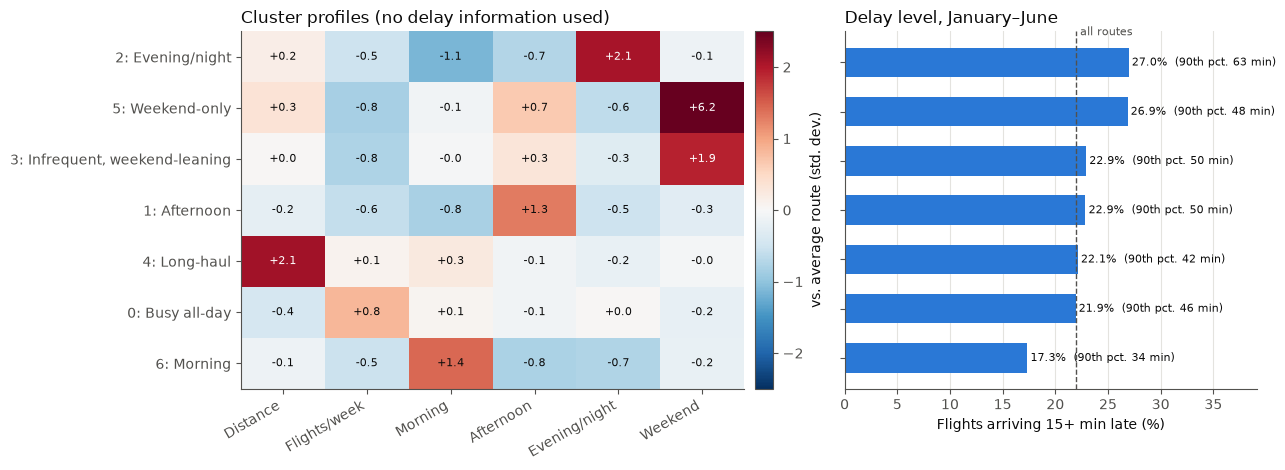

In [5]:
# Figure: what each cluster looks like (left) and how late it is (right)
order = cluster_delays.drop(index="all").sort_values("late_15_share", ascending=False).index  # latest at the top
labels = [f"{c}: {CLUSTER_NAMES[c]}" for c in order]

feature_labels = {
    "mean_distance": "Distance", "flights_per_week": "Flights/week", "morning_share": "Morning",
    "afternoon_share": "Afternoon", "evening_night_share": "Evening/night", "weekend_share": "Weekend",
}
# Each profile value relative to the average route, in standard deviations
z = (profiles.loc[order, PROFILE_COLS] - overall) / routes[PROFILE_COLS].std()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})

im = ax1.imshow(z.to_numpy(), cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
ax1.set_xticks(range(len(PROFILE_COLS)), [feature_labels[c] for c in PROFILE_COLS], rotation=30, ha="right")
ax1.set_yticks(range(len(order)), labels)
ax1.grid(False)
for (i, j), v in np.ndenumerate(z.to_numpy()):
    ax1.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8,
             color="white" if abs(v) > 1.5 else INK)
fig.colorbar(im, ax=ax1, fraction=0.04, pad=0.02, label="vs. average route (std. dev.)")
ax1.set_title("Cluster profiles (no delay information used)", loc="left", color=INK)

late = cluster_delays.loc[order, "late_15_share"] * 100
p90 = cluster_delays.loc[order, "p90_delay"]
ax2.barh(range(len(order)), late, color=PALETTE[0], height=0.6)
ax2.axvline(all_row["late_15_share"] * 100, color=INK_MUTED, linestyle="--", linewidth=1)
ax2.invert_yaxis()  # row 0 at the top, same order as the heatmap
ax2.text(all_row["late_15_share"] * 100, -0.55, " all routes", color=INK_MUTED, fontsize=8)
for i, (v, q) in enumerate(zip(late, p90)):
    ax2.text(v + 0.3, i, f"{v:.1f}%  (90th pct. {q:.0f} min)", va="center", fontsize=8, color=INK)
ax2.set_yticks(range(len(order)), [""] * len(order))
ax2.set_xlim(0, late.max() * 1.45)
ax2.set_xlabel("Flights arriving 15+ min late (%)")
ax2.set_title("Delay level, January–June", loc="left", color=INK)
ax2.grid(axis="y", visible=False)

fig.tight_layout()
if DATA_SOURCE == "full":
    fig.savefig(FIGURES_DIR / "02b_cluster_profiles_delays.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Delay causes per cluster

For late flights (15+ minutes), the dataset splits the delay minutes into five causes. We compare each cluster's share of
minutes per cause with the share over all clusters. A cluster with a high **late incoming aircraft** share suffers more from
delays passed on from earlier flights, which is the network effect this project is about.

In [6]:
late_flights = flights.loc[flights["late_15"] == 1]
cause_minutes = late_flights.groupby("cluster")[DELAY_CAUSES].sum()
cause_shares = cause_minutes.div(cause_minutes.sum(axis=1), axis=0) * 100
overall_shares = late_flights[DELAY_CAUSES].sum() / late_flights[DELAY_CAUSES].sum().sum() * 100
cause_diff = cause_shares - overall_shares  # percentage points above (+) or below (-) the average

cause_table = cause_shares.rename(columns=CAUSE_LABELS)
cause_table.insert(0, "name", pd.Series(CLUSTER_NAMES))
cause_table.insert(1, "late_flights", late_flights.groupby("cluster").size())
cause_table.loc["all"] = ["All clusters", len(late_flights), *overall_shares.to_numpy()]

print("Share of delay minutes per cause (%)")
display(cause_table.style.format({c: "{:.1f}" for c in CAUSE_LABELS.values()} | {"late_flights": "{:,.0f}"}))

print("Difference from the average (percentage points)")
display(cause_diff.rename(columns=CAUSE_LABELS).rename(index=CLUSTER_NAMES).round(1))

Share of delay minutes per cause (%)


,name,late_flights,Airline,Weather,Air traffic system,Security,Late incoming aircraft
cluster,,,,,,,
0,Busy all-day,"509,769",31.7,6.6,19.3,0.2,42.3
1,Afternoon,"53,497",30.4,7.5,20.0,0.2,42.0
2,Evening/night,"50,642",33.0,7.4,16.1,0.3,43.2
3,"Infrequent, weekend-leaning","8,902",29.2,6.5,24.3,0.2,39.8
4,Long-haul,"75,089",38.4,3.8,21.8,0.2,35.8
5,Weekend-only,"1,459",23.0,4.5,23.3,0.2,49.1
6,Morning,"42,785",38.9,7.9,22.2,0.1,30.8
all,All clusters,"742,143",32.7,6.5,19.6,0.2,41.0


Difference from the average (percentage points)


,Airline,Weather,Air traffic system,Security,Late incoming aircraft
cluster,,,,,
Busy all-day,-1.0,0.0,-0.3,-0.0,1.3
Afternoon,-2.4,1.0,0.4,-0.0,1.0
Evening/night,0.3,0.9,-3.5,0.1,2.3
"Infrequent, weekend-leaning",-3.5,-0.0,4.7,0.0,-1.2
Long-haul,5.7,-2.7,2.2,0.0,-5.2
Weekend-only,-9.8,-2.0,3.7,-0.0,8.1
Morning,6.2,1.4,2.6,-0.1,-10.1


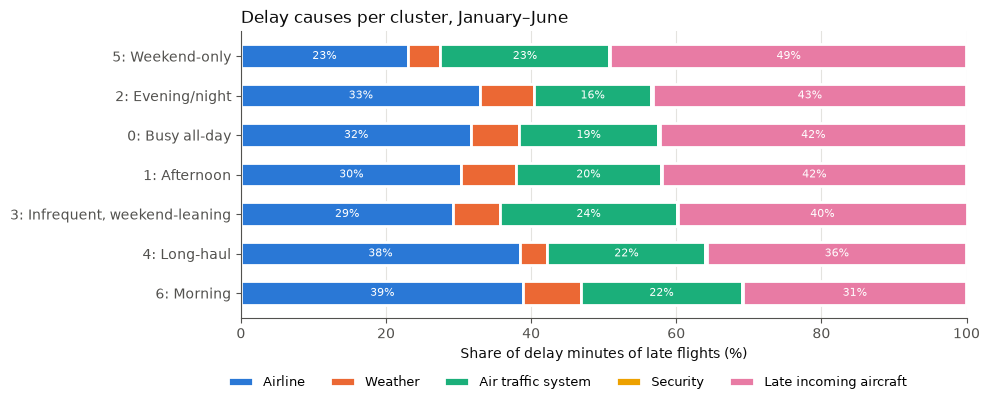

In [7]:
# Figure: stacked shares of delay minutes per cause
order_c = cause_shares.sort_values("late_aircraft_delay").index
fig, ax = plt.subplots(figsize=(10, 4.2))
left = np.zeros(len(order_c))
for i, cause in enumerate(DELAY_CAUSES):
    vals = cause_shares.loc[order_c, cause].to_numpy()
    ax.barh(range(len(order_c)), vals, left=left, color=PALETTE[i], height=0.6,
            edgecolor="white", linewidth=2, label=CAUSE_LABELS[cause])
    for j, (l, v) in enumerate(zip(left, vals)):
        if v >= 8:
            ax.text(l + v / 2, j, f"{v:.0f}%", ha="center", va="center", fontsize=8, color="white")
    left += vals
ax.set_yticks(range(len(order_c)), [f"{c}: {CLUSTER_NAMES[c]}" for c in order_c])
ax.set_xlim(0, 100)
ax.set_xlabel("Share of delay minutes of late flights (%)")
ax.set_title("Delay causes per cluster, January–June", loc="left", color=INK)
ax.grid(axis="y", visible=False)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.45, -0.16), frameon=False, fontsize=9)
fig.tight_layout()
if DATA_SOURCE == "full":
    fig.savefig(FIGURES_DIR / "02b_delay_causes_by_cluster.png", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
# Short written summary, generated from the numbers above
cd = cluster_delays.drop(index="all")
worst, best = cd["late_15_share"].idxmax(), cd["late_15_share"].idxmin()
la = cause_shares["late_aircraft_delay"]
la_hi, la_lo = la.idxmax(), la.idxmin()
air = cause_shares["carrier_delay"]

print(f"- Latest cluster: {worst} ({CLUSTER_NAMES[worst]}), {cd.loc[worst, 'late_15_share']:.1%} late, "
      f"90th percentile {cd.loc[worst, 'p90_delay']:.0f} min.")
print(f"- Most punctual cluster: {best} ({CLUSTER_NAMES[best]}), {cd.loc[best, 'late_15_share']:.1%} late, "
      f"90th percentile {cd.loc[best, 'p90_delay']:.0f} min.")
print(f"- All clusters together: {all_row['late_15_share']:.1%} late; medians range from "
      f"{cd['median_delay'].min():.0f} to {cd['median_delay'].max():.0f} min, so the typical flight is early "
      f"in every cluster and the differences sit in the tail.")
print(f"- Late incoming aircraft: highest share in cluster {la_hi} ({CLUSTER_NAMES[la_hi]}, {la[la_hi]:.0f}%), "
      f"lowest in cluster {la_lo} ({CLUSTER_NAMES[la_lo]}, {la[la_lo]:.0f}%); average {overall_shares['late_aircraft_delay']:.0f}%.")
print(f"- Airline-caused delays: highest share in cluster {air.idxmax()} ({CLUSTER_NAMES[air.idxmax()]}, {air.max():.0f}%).")

- Latest cluster: 2 (Evening/night), 27.0% late, 90th percentile 63 min.
- Most punctual cluster: 6 (Morning), 17.3% late, 90th percentile 34 min.
- All clusters together: 22.0% late; medians range from -8 to -2 min, so the typical flight is early in every cluster and the differences sit in the tail.
- Late incoming aircraft: highest share in cluster 5 (Weekend-only, 49%), lowest in cluster 6 (Morning, 31%); average 41%.
- Airline-caused delays: highest share in cluster 6 (Morning, 39%).


## 4. Scalability: hierarchical clustering against K-Means

Notebook 02 ran hierarchical clustering (Ward linkage) on a sample of 3,000 routes only. The reason: it compares every
route with every other route, so time and memory grow roughly with the **square** of the number of routes, while
K-Means grows roughly **linearly**. Here we measure both on increasing numbers of routes, using the same five Model B
features. Runtimes are the median of 3 runs. Peak memory comes from one extra Ward run, which is also written to
`results/logs/performance_log.csv`.

The "distance matrix" column is the memory needed just to store all pairwise distances (n × (n − 1) / 2 numbers of 8 bytes).
This part only uses the exported route table, so the result is the same with the sample or the full flight data.

In [9]:
X_all = StandardScaler().fit_transform(routes[FEATURES_B])
rng = np.random.default_rng(RANDOM_SEED)
sizes = [s for s in [500, 1000, 2000, 4000, 6000, 8000] if s < len(X_all)] + [len(X_all)]

N_REPEATS = 3
KMeans(n_clusters=n_clusters, random_state=RANDOM_SEED, n_init=10).fit(X_all[:500])  # warm-up, not timed


def median_runtime(fit, X):
    times = []
    for _ in range(N_REPEATS):
        t0 = time.perf_counter()
        fit(X)
        times.append(time.perf_counter() - t0)
    return float(np.median(times))


fit_kmeans = lambda X: KMeans(n_clusters=n_clusters, random_state=RANDOM_SEED, n_init=10).fit(X)
fit_ward = lambda X: AgglomerativeClustering(n_clusters=n_clusters, linkage="ward").fit(X)

rows = []
for n in sizes:
    X = X_all[rng.choice(len(X_all), size=n, replace=False)]
    km_s = median_runtime(fit_kmeans, X)
    ward_s = median_runtime(fit_ward, X)
    # One extra tracked Ward run for peak memory; it is also written to the performance log
    with track("rq1_ward_runtime", n_routes=n, k=n_clusters, kmeans_median_s=round(km_s, 3)) as hc:
        fit_ward(X)
    rows.append({
        "n_routes": n,
        "kmeans_s": km_s,
        "ward_s": ward_s,
        "ward_peak_python_mb": hc["peak_python_mb"],
        "distance_matrix_mb": n * (n - 1) / 2 * 8 / 1024**2,
    })

runtime = pd.DataFrame(rows)
runtime["ward_vs_kmeans"] = runtime["ward_s"] / runtime["kmeans_s"]

# Growth exponent: slope of log(time) against log(n) over the larger sizes
big = runtime[runtime["n_routes"] >= 2000]
slope_km = np.polyfit(np.log(big["n_routes"]), np.log(big["kmeans_s"]), 1)[0]
slope_hc = np.polyfit(np.log(big["n_routes"]), np.log(big["ward_s"]), 1)[0]

display(runtime.round(3))
print(f"Time grows like n^{slope_km:.1f} for K-Means and n^{slope_hc:.1f} for Ward "
      f"(1 = linear, 2 = quadratic).")

[rq1_ward_runtime] runtime: 0.01 s | peak memory (Python/pandas): 1.1 MB | peak memory (pyarrow pool): 1049.0 MB
[rq1_ward_runtime] runtime: 0.07 s | peak memory (Python/pandas): 4.3 MB | peak memory (pyarrow pool): 1049.0 MB
[rq1_ward_runtime] runtime: 0.23 s | peak memory (Python/pandas): 17.2 MB | peak memory (pyarrow pool): 1049.0 MB
[rq1_ward_runtime] runtime: 0.92 s | peak memory (Python/pandas): 68.7 MB | peak memory (pyarrow pool): 1049.0 MB
[rq1_ward_runtime] runtime: 2.07 s | peak memory (Python/pandas): 154.5 MB | peak memory (pyarrow pool): 1049.0 MB
[rq1_ward_runtime] runtime: 4.00 s | peak memory (Python/pandas): 274.6 MB | peak memory (pyarrow pool): 1049.0 MB
[rq1_ward_runtime] runtime: 6.71 s | peak memory (Python/pandas): 426.7 MB | peak memory (pyarrow pool): 1049.0 MB


,n_routes,kmeans_s,ward_s,ward_peak_python_mb,distance_matrix_mb,ward_vs_kmeans
0,500,0.060,0.004,1.1,0.952,0.064
1,1000,0.059,0.033,4.3,3.811,0.560
2,2000,0.077,0.141,17.2,15.251,1.838
3,4000,0.112,0.671,68.7,61.020,5.976
4,6000,0.115,1.792,154.5,137.306,15.529
5,8000,0.155,3.594,274.6,244.110,23.223
6,9972,0.187,6.489,426.7,379.298,34.641


Time grows like n^0.5 for K-Means and n^2.4 for Ward (1 = linear, 2 = quadratic).


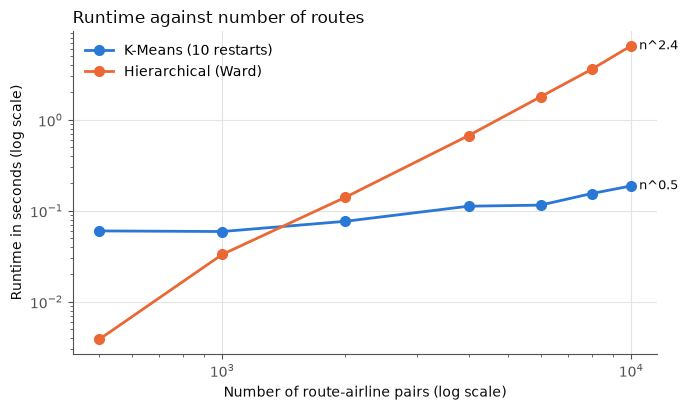

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(runtime["n_routes"], runtime["kmeans_s"], marker="o", markersize=7, linewidth=2,
        color=PALETTE[0], label="K-Means (10 restarts)")
ax.plot(runtime["n_routes"], runtime["ward_s"], marker="o", markersize=7, linewidth=2,
        color=PALETTE[1], label="Hierarchical (Ward)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Number of route-airline pairs (log scale)")
ax.set_ylabel("Runtime in seconds (log scale)")
ax.set_title("Runtime against number of routes", loc="left", color=INK)
last = runtime.iloc[-1]
ax.annotate(f"n^{slope_km:.1f}", (last["n_routes"], last["kmeans_s"]), xytext=(6, 0),
            textcoords="offset points", va="center", color=INK, fontsize=9)
ax.annotate(f"n^{slope_hc:.1f}", (last["n_routes"], last["ward_s"]), xytext=(6, 0),
            textcoords="offset points", va="center", color=INK, fontsize=9)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02b_clustering_runtime.png", dpi=200, bbox_inches="tight")
plt.show()

## Export

Tables and figures are only written when the full data was used, so test runs on the sample never overwrite report results.
The runtime table does not depend on the flight data and is always written.

In [11]:
runtime.to_csv(TABLES_DIR / "02b_clustering_runtime.csv", index=False)

if DATA_SOURCE == "full":
    profiles.to_csv(TABLES_DIR / "02b_cluster_profiles.csv")
    cluster_delays.to_csv(TABLES_DIR / "02b_cluster_delay_percentiles.csv")
    cause_table.to_csv(TABLES_DIR / "02b_delay_causes_by_cluster.csv")
    cause_diff.rename(columns=CAUSE_LABELS).to_csv(TABLES_DIR / "02b_delay_causes_vs_average.csv")
    print("Exported 02b tables and figures (full data).")
else:
    print("Sample run: only 02b_clustering_runtime.csv was written. Re-run with the full data for the other tables.")

Exported 02b tables and figures (full data).
